# 02 — Correlation and Feature Selection
Compare predictor values at month t with the target at month t+1

In [17]:
from pathlib import Path
import sys, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve project root from any nested notebook directory.
HERE = Path.cwd().resolve()
REPO_ROOT = next((p for p in [HERE, *HERE.parents] if (p / "src" / "features.py").exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook somewhere inside the project folder containing src/features.py.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from src.features import create_lagged_features

DATA_FILE = REPO_ROOT / "Data" / "lithium_consolidated_monthly.csv"
RESULTS_DIR = REPO_ROOT / "Results"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Selected lithium carbonate price (CNY/t)"
JAPAN_INDEX = "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
RANDOM_STATE = 42
df = pd.read_csv(DATA_FILE)
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").drop_duplicates("Month").set_index("Month").asfreq("MS")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
print("Project root:", REPO_ROOT)
print("Data:", DATA_FILE)

Project root: /home/schmidlucy/Lucy-Schmid.github.io
Data: /home/schmidlucy/Lucy-Schmid.github.io/Data/lithium_consolidated_monthly.csv


In [18]:
excluded={TARGET,"Selected target source","Lithium carbonate price (CNY/metric tonne)",
"China spot lithium carbonate price (CNY/t) - CSV","OLD - faulty cobalt settlement series (constant; excluded)",
"China spot price open (CNY/t) - CSV","China spot price high (CNY/t) - CSV",
"China spot price low (CNY/t) - CSV","China spot price volume (CSV)","China spot price change (%) - CSV"}
predictors=[c for c in df.select_dtypes(include=np.number).columns if c not in excluded]
aligned=df[predictors].join(df[TARGET].shift(-1).rename("Next-month target"))
corr=aligned.corr(numeric_only=True)["Next-month target"].drop("Next-month target").dropna()
corr_table=corr.rename("Correlation").to_frame()
corr_table["Absolute correlation"]=corr_table["Correlation"].abs()
corr_table=corr_table.sort_values("Absolute correlation",ascending=False)
display(corr_table.head(25)); corr_table.to_csv(TABLES_DIR/"next_month_predictor_correlations.csv")

,Correlation,Absolute correlation
LME lithium hydroxide price (USD/metric tonne),0.904326,0.904326
Albemarle share price (USD/share),0.826980,0.826980
SQM share price (USD/ADR),0.808427,0.808427
LME nickel price (USD/metric tonne),0.794102,0.794102
Japan lithium battery inventory (thousands),0.731348,0.731348
"Japan, Inventory - Lithium Batteries",0.619242,0.619242
"Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100",0.575093,0.575093
LME cobalt cash price (USD/metric tonne) - updated Datastream,0.520258,0.520258
"China, Lithium Ion Battery Production",0.515940,0.515940
CNY/USD exchange-rate series (source quote),-0.291093,0.291093


## Correlation ranking

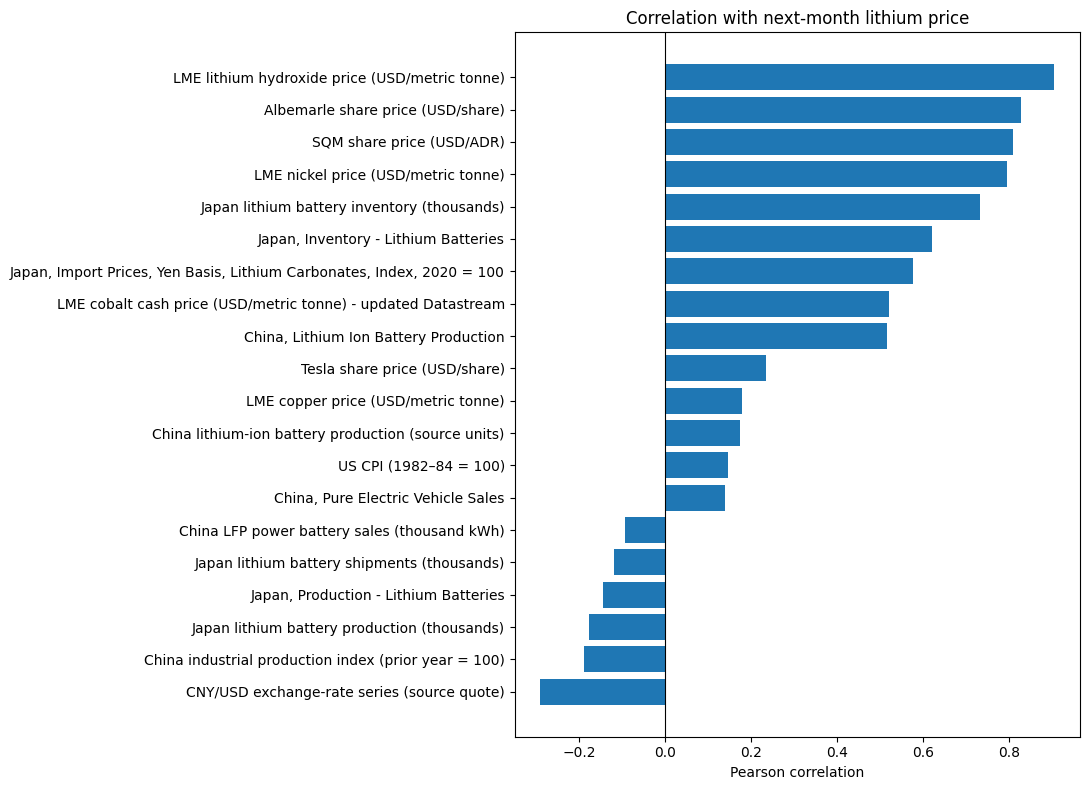

In [19]:
top=corr_table.head(20).sort_values("Correlation")
fig,ax=plt.subplots(figsize=(11,8)); ax.barh(top.index,top["Correlation"])
ax.axvline(0,color="black",linewidth=.8); ax.set(title="Correlation with next-month lithium price",xlabel="Pearson correlation")
plt.tight_layout(); fig.savefig(FIGURES_DIR/"04_predictor_correlation_ranking.png",dpi=180); plt.show()

## Correlation heatmap

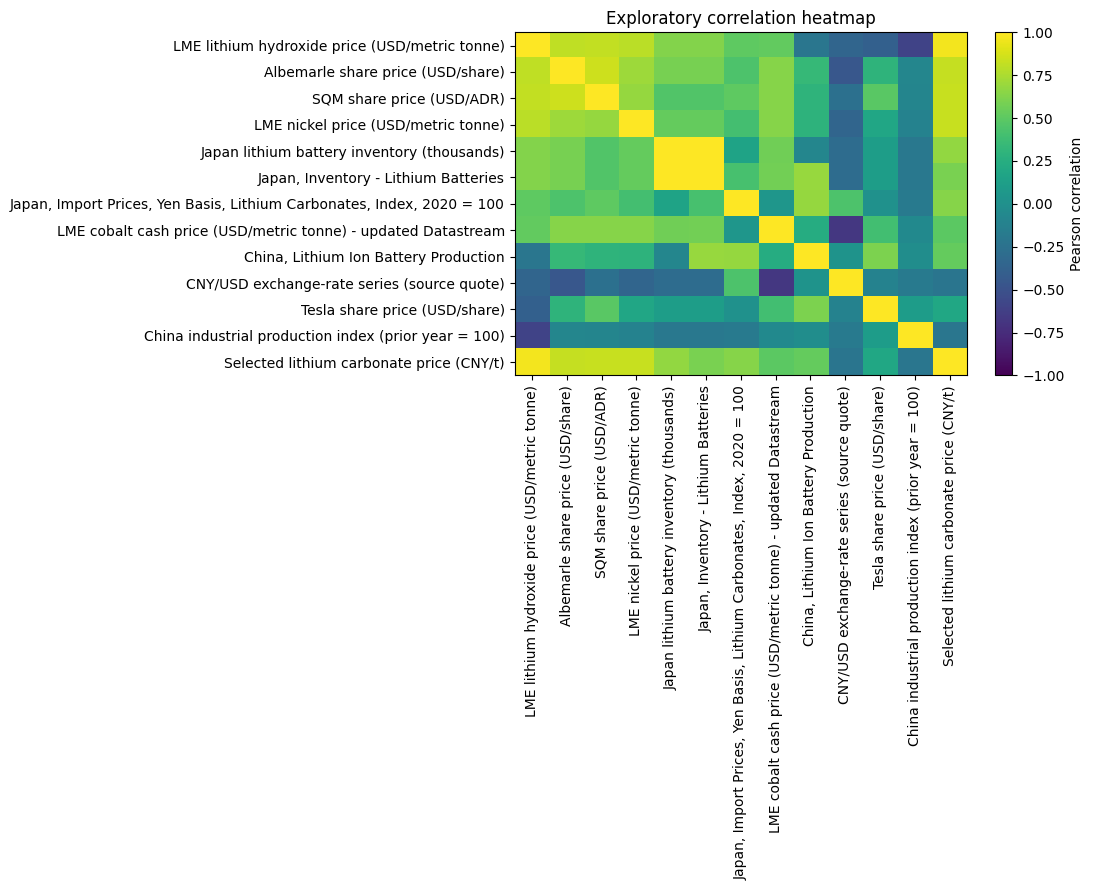

,Correlation,Absolute correlation
"Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100",0.575093,0.575093


In [20]:
cols=corr_table.head(12).index.tolist()+[TARGET]
mat=df[cols].corr()
fig,ax=plt.subplots(figsize=(11,9)); im=ax.imshow(mat,vmin=-1,vmax=1,aspect="auto")
ax.set_xticks(range(len(cols)),cols,rotation=90); ax.set_yticks(range(len(cols)),cols)
fig.colorbar(im,ax=ax,label="Pearson correlation"); ax.set_title("Exploratory correlation heatmap")
plt.tight_layout(); fig.savefig(FIGURES_DIR/"05_correlation_heatmap.png",dpi=180); plt.show()
if JAPAN_INDEX in corr_table.index: display(corr_table.loc[[JAPAN_INDEX]])